# Semaine 4 - Exploratory Data Analysis (EDA)

## Objectif
Explorer le dataset SMS Spam Collection pour mieux comprendre
les caractéristiques des messages Ham et Spam à l'aide de statistiques
descriptives et de visualisations.

In [22]:
import pandas as pd 
import matplotlib.pyplot as plt
df= pd.read_csv("../data/processed/sms_spam_collection.csv",sep='\t')


### 1. Répartition des classes

D'après l'audit réalisé en semaine 3, le dataset contient :
- 86,6 % de messages Ham.
- 13,4 % de messages Spam.

Nous allons maintenant représenter cette répartition graphiquement
pour mieux visualiser le déséquilibre entre les deux classes.

In [16]:
repartition=df["label"].value_counts()

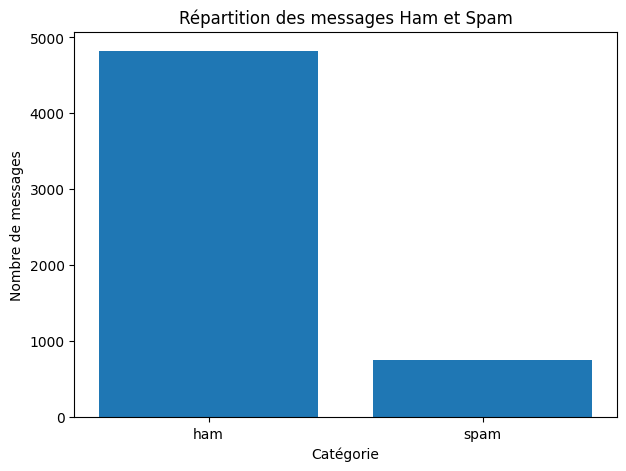

In [32]:
plt.figure(figsize=(7,5))
plt.bar(repartition.index,repartition.values)
plt.title("Répartition des messages Ham et Spam")
plt.xlabel("Catégorie")
plt.ylabel("Nombre de messages")
plt.show()


### Interprétation

Le graphique montre que les messages Ham sont largement
majoritaires par rapport aux messages Spam.
Le dataset contient 4 827 messages Ham contre 747 messages Spam.
Cela confirme le déséquilibre des classes observé lors de la semaine 3.

### 2 Comparaison des longueurs de messages ham/spam.

In [33]:
df.groupby("label")["longueur_caracteres"].mean()

label
ham      71.471929
spam    138.676037
Name: longueur_caracteres, dtype: float64

### Interprétation
La longueur moyenne des messages Ham est d'environ 71 caractères,
contre 139 caractères pour les messages Spam.
On observe donc que les messages Spam sont en moyenne plus longs
que les messages Ham.

<function matplotlib.pyplot.show(close=None, block=None)>

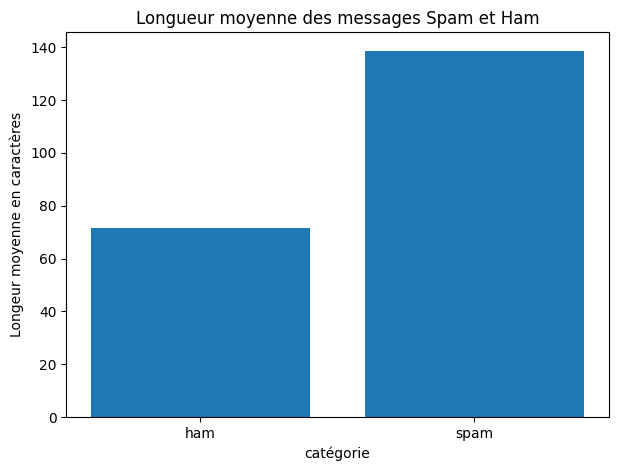

In [37]:
longueur_moyenne = df.groupby("label")["longueur_caracteres"].mean()
plt.figure(figsize=(7,5))
plt.bar(longueur_moyenne.index,longueur_moyenne.values)
plt.title("Longueur moyenne des messages Spam et Ham")
plt.xlabel("catégorie")
plt.ylabel("Longeur moyenne en caractères")
plt.show


## Distribution de la longueur des messages

Dans cette partie, nous allons étudier la distribution de la longueur des SMS à l'aide d'un histogramme.

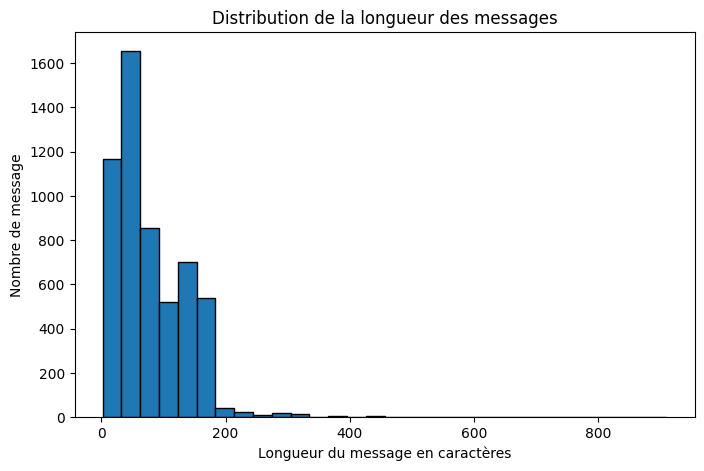

In [84]:
plt.figure(figsize=(8,5))
plt.hist(df["longueur_caracteres"],bins=30,edgecolor="black")
plt.title("Distribution de la longueur des messages")
plt.xlabel("Longueur du message en caractères")
plt.ylabel("Nombre de message")
plt.show()

### Interprétation

L'histogramme montre que la majorité des messages ont une longueur relativement courte.
Le nombre de messages diminue lorsque la longueur augmente.
On observe également quelques messages très longs, ce qui donne à la distribution une asymétrie vers la droite.

## 3. Affichage des messages courts et longs

Dans cette partie, nous allons examiner quelques messages courts et longs du dataset.

L'objectif est d'observer leur contenu et de mieux comprendre les différences éventuelles entre les messages Ham et Spam.

### 3.1 Les messages les plus courts

Nous allons trier les messages selon leur longueur, dans l'ordre croissant, afin d'afficher les 5 messages les plus courts.

In [40]:
df.sort_values("longueur_caracteres").head()

,label,message,longueur_caracteres
5359,ham,Ok,2
1925,ham,Ok,2
4498,ham,Ok,2
3051,ham,Ok,2
3492,ham,Ok.,3


### 3.2 Les messages les plus longs

Nous allons maintenant effectuer le même tri dans l'ordre décroissant afin d'afficher les 5 messages les plus longs.

In [43]:
df.sort_values("longueur_caracteres", ascending=False).head()

,label,message,longueur_caracteres
1085,ham,For me the love should start with attraction.i...,910
1863,ham,The last thing i ever wanted to do was hurt yo...,790
2434,ham,Indians r poor but India is not a poor country...,629
1579,ham,How to Make a girl Happy? It's not at all diff...,611
2158,ham,Sad story of a Man - Last week was my b'day. M...,588


### 4 . Les mots frequents
### Préparation du texte
Pour étudier les mots fréquents, nous devons d'abord préparer les messages.
- récupérer tous les messages sous forme d'une seule chaîne de caractères.
- Transformer les messages en minuscules.
- Supprimer les signes de ponctuation.
- Séparer chaque message en une liste de mots.

In [ ]:
import string
from collections import Counter
tous_les_messages=" ".join(df["message"].str.lower())
tous_les_messages=tous_les_messages.translate(str.maketrans("","",string.punctuation))
tous_les_messages=tous_les_messages.split()
print(tous_les_messages[:20])

['go', 'until', 'jurong', 'point', 'crazy', 'available', 'only', 'in', 'bugis', 'n', 'great', 'world', 'la', 'e', 'buffet', 'cine', 'there', 'got', 'amore', 'wat']
Counter({'to': 2251, 'i': 2239, 'you': 2128, 'a': 1442, 'the': 1333, 'u': 1132, 'and': 971, 'is': 893, 'in': 888, 'me': 791, 'my': 757, 'for': 710, 'your': 677, 'it': 622, 'of': 620, 'call': 578, 'have': 576, 'on': 536, 'that': 514, 'are': 490, '2': 482, 'now': 478, 'im': 464, 'so': 439, 'not': 436, 'but': 432, 'or': 417, 'at': 405, 'can': 405, 'do': 401, 'ur': 390, 'get': 386, 'be': 385, 'will': 383, 'if': 383, 'with': 382, 'just': 368, 'we': 346, 'no': 334, 'this': 330, 'its': 309, 'up': 305, '4': 293, 'dont': 287, 'when': 286, 'go': 281, 'ok': 278, 'from': 278, 'ltgt': 276, 'free': 275, 'all': 269, 'out': 267, 'how': 264, 'what': 261, 'know': 257, 'like': 244, 'got': 239, 'ill': 239, 'good': 236, 'then': 233, 'was': 231, 'come': 229, 'am': 224, 'only': 211, 'time': 208, 'day': 203, 'love': 200, 'there': 196, 'want': 193, 

In [71]:
frequence=Counter(tous_les_messages)
print(frequence)
frequence.most_common(10)

Counter({'to': 2251, 'i': 2239, 'you': 2128, 'a': 1442, 'the': 1333, 'u': 1132, 'and': 971, 'is': 893, 'in': 888, 'me': 791, 'my': 757, 'for': 710, 'your': 677, 'it': 622, 'of': 620, 'call': 578, 'have': 576, 'on': 536, 'that': 514, 'are': 490, '2': 482, 'now': 478, 'im': 464, 'so': 439, 'not': 436, 'but': 432, 'or': 417, 'at': 405, 'can': 405, 'do': 401, 'ur': 390, 'get': 386, 'be': 385, 'will': 383, 'if': 383, 'with': 382, 'just': 368, 'we': 346, 'no': 334, 'this': 330, 'its': 309, 'up': 305, '4': 293, 'dont': 287, 'when': 286, 'go': 281, 'ok': 278, 'from': 278, 'ltgt': 276, 'free': 275, 'all': 269, 'out': 267, 'how': 264, 'what': 261, 'know': 257, 'like': 244, 'got': 239, 'ill': 239, 'good': 236, 'then': 233, 'was': 231, 'come': 229, 'am': 224, 'only': 211, 'time': 208, 'day': 203, 'love': 200, 'there': 196, 'want': 193, 'send': 191, 'text': 188, 'he': 184, 'as': 180, 'by': 172, 'going': 171, 'one': 171, 'ü': 169, 'need': 167, 'about': 166, 'txt': 163, 'home': 162, 'lor': 160, 'see'

[('to', 2251),
 ('i', 2239),
 ('you', 2128),
 ('a', 1442),
 ('the', 1333),
 ('u', 1132),
 ('and', 971),
 ('is', 893),
 ('in', 888),
 ('me', 791)]

### observation des mots fréquents
Les 10 mots les plus fréquents dans l'ensemble du dataset sont principalement des mots courants en anglais, comme "to", "i", "you" et "the".
Ces mots apparaissent fréquemment, mais ne permettent pas nécessairement de distinguer les messages Ham des messages Spam.
Certains de ces mots sont appelés Stop Words.

####  Mots fréquents dans les messages Ham

Nous allons sélectionner les messages Ham, préparer leur texte, puis compter les occurrences de chaque mot.

In [74]:
messages_ham=" ".join(df[df["label"]=="ham"]["message"].str.lower())
print(messages_ham[:200])

go until jurong point, crazy.. available only in bugis n great world la e buffet... cine there got amore wat... ok lar... joking wif u oni... u dun say so early hor... u c already then say... nah i do


####  Nettoyage et préparation des messages Ham

Nous supprimons les signes de ponctuation, puis nous séparons les messages en mots afin de pouvoir compter leurs occurrences.

In [75]:
messages_ham=messages_ham.translate(str.maketrans("","",string.punctuation))
messages_ham=messages_ham.split()
print(messages_ham)


['go', 'until', 'jurong', 'point', 'crazy', 'available', 'only', 'in', 'bugis', 'n', 'great', 'world', 'la', 'e', 'buffet', 'cine', 'there', 'got', 'amore', 'wat', 'ok', 'lar', 'joking', 'wif', 'u', 'oni', 'u', 'dun', 'say', 'so', 'early', 'hor', 'u', 'c', 'already', 'then', 'say', 'nah', 'i', 'dont', 'think', 'he', 'goes', 'to', 'usf', 'he', 'lives', 'around', 'here', 'though', 'even', 'my', 'brother', 'is', 'not', 'like', 'to', 'speak', 'with', 'me', 'they', 'treat', 'me', 'like', 'aids', 'patent', 'as', 'per', 'your', 'request', 'melle', 'melle', 'oru', 'minnaminunginte', 'nurungu', 'vettam', 'has', 'been', 'set', 'as', 'your', 'callertune', 'for', 'all', 'callers', 'press', '9', 'to', 'copy', 'your', 'friends', 'callertune', 'im', 'gonna', 'be', 'home', 'soon', 'and', 'i', 'dont', 'want', 'to', 'talk', 'about', 'this', 'stuff', 'anymore', 'tonight', 'k', 'ive', 'cried', 'enough', 'today', 'ive', 'been', 'searching', 'for', 'the', 'right', 'words', 'to', 'thank', 'you', 'for', 'this

####  Comptage des mots fréquents dans les messages Ham

Nous utilisons Counter() pour compter les occurrences de chaque mot, puis most_common(10) pour afficher les 10 mots les plus fréquents.

In [77]:
frequence_ham=Counter(messages_ham)
frequence_ham.most_common(10)

[('i', 2194),
 ('you', 1841),
 ('to', 1562),
 ('the', 1129),
 ('a', 1064),
 ('u', 985),
 ('and', 849),
 ('in', 815),
 ('me', 761),
 ('my', 747)]

####  Mots fréquents dans les messages Spam

Nous allons sélectionner uniquement les messages Spam, préparer leur texte et compter les occurrences de chaque mot.

In [80]:
messages_spam=" ".join(df[df["label"]=="spam"]["message"].str.lower())
messages_spam=messages_spam.translate(str.maketrans("","",string.punctuation))
messages_spam=messages_spam.split()
print(messages_spam)
frequence_spam=Counter(messages_spam)
frequence_spam.most_common(10)

['free', 'entry', 'in', '2', 'a', 'wkly', 'comp', 'to', 'win', 'fa', 'cup', 'final', 'tkts', '21st', 'may', '2005', 'text', 'fa', 'to', '87121', 'to', 'receive', 'entry', 'questionstd', 'txt', 'ratetcs', 'apply', '08452810075over18s', 'freemsg', 'hey', 'there', 'darling', 'its', 'been', '3', 'weeks', 'now', 'and', 'no', 'word', 'back', 'id', 'like', 'some', 'fun', 'you', 'up', 'for', 'it', 'still', 'tb', 'ok', 'xxx', 'std', 'chgs', 'to', 'send', '£150', 'to', 'rcv', 'winner', 'as', 'a', 'valued', 'network', 'customer', 'you', 'have', 'been', 'selected', 'to', 'receivea', '£900', 'prize', 'reward', 'to', 'claim', 'call', '09061701461', 'claim', 'code', 'kl341', 'valid', '12', 'hours', 'only', 'had', 'your', 'mobile', '11', 'months', 'or', 'more', 'u', 'r', 'entitled', 'to', 'update', 'to', 'the', 'latest', 'colour', 'mobiles', 'with', 'camera', 'for', 'free', 'call', 'the', 'mobile', 'update', 'co', 'free', 'on', '08002986030', 'six', 'chances', 'to', 'win', 'cash', 'from', '100', 'to',

[('to', 689),
 ('a', 378),
 ('call', 347),
 ('you', 287),
 ('your', 263),
 ('free', 216),
 ('the', 204),
 ('for', 203),
 ('now', 189),
 ('or', 188)]

### Visualisation des 10 mots les plus fréquents dans les messages Spam
Nous allons représenter les 10 mots les plus fréquents dans les messages Spam à l'aide d'un graphique en barres.

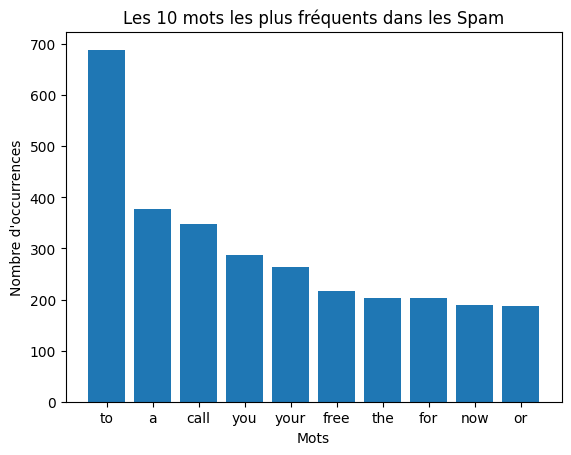

In [85]:
mots_frequents=frequence_spam.most_common(10)
mots=[mot[0]for mot in mots_frequents]
nombres=[mot[1]for mot in mots_frequents]
plt.bar(mots,nombres)
plt.title("Les 10 mots les plus fréquents dans les Spam")
plt.xlabel("Mots")
plt.ylabel("Nombre d'occurrences")
plt.show()

### Interprétation

Le graphique montre que le mot "to" est le plus fréquent dans les messages Spam, suivi de "a", "call" et "you".
On remarque également la présence de mots comme "free", "your" et "now" parmi les 10 mots les plus fréquents.
Certains de ces mots pourraient être associés aux messages indésirables. Cependant, leur présence ne suffit pas à identifier un Spam, car certains mots sont également utilisés dans les messages légitimes.
Cette analyse constitue une première observation et devra être approfondie lors de la construction des modèles de classification.

### Comparaison et interprétation
L'analyse des mots fréquents montre des différences entre les messages Ham et Spam.
- Les messages Ham contiennent principalement des mots courants dans les conversations personnelles, comme "i", "you", "me" et "my".
- Les messages Spam contiennent notamment des mots comme "call", "free", "your" et "now", qui peuvent être associés à des offres ou à des messages promotionnels.
- Certains mots, comme "to", "a", "you" et "the", sont fréquents dans les deux catégories.
Ces résultats permettent de formuler des premières hypothèses sur le vocabulaire utilisé dans les messages Spam et Ham.
Cependant, la présence d'un mot ne suffit pas à déterminer la catégorie d'un message.

## 5. Observations et hypothèses
### 5.1 Observations
À partir de l'analyse exploratoire, nous avons relevé les observations suivantes :
1. Le dataset contient davantage de messages Ham (86,6 %) que de messages Spam (13,4 %).
2. La longueur moyenne des messages Ham est d'environ 71 caractères, contre 139 caractères pour les messages Spam.
3. Les messages du dataset présentent des longueurs variables : certains sont très courts, tandis que d'autres sont beaucoup plus longs.
4. Dans les messages Ham, les mots les plus fréquents sont principalement des mots courants de conversation, comme "i", "you", "me" et "my".
5. Dans les messages Spam, des mots comme "call", "free", "your" et "now" apparaissent parmi les plus fréquents.

### 5.2 Hypothèses à tester ultérieurement

À partir des observations réalisées, nous formulons les hypothèses suivantes :
1. Les messages plus longs ont davantage tendance à être des Spam que les messages courts.
2. La présence de certains mots, comme "free", "call" et "win", pourrait être associée aux messages Spam.
3. La combinaison de plusieurs mots pourrait permettre de mieux distinguer les messages Ham des messages Spam qu'un seul mot pris isolément.